In [11]:
# Import the required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Create folders to store the outputs
for folder in ["data", "images", "results", "models"]:
    os.makedirs(folder, exist_ok=True)

In [12]:
from google.colab import files

# Select vgsales.csv from your computer when prompted
uploaded = files.upload()

df = pd.read_csv("vgsales.csv")

# Keep a safe copy of the original dataset
df.to_csv("data/vgsales.csv", index=False)

print("Total rows and columns:", df.shape)
print("\nColumn data types:")
print(df.dtypes)
print("\nMissing values in each column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())
df.head()

Saving vgsales.csv to vgsales (3).csv
Total rows and columns: (16598, 11)

Column data types:
Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

Missing values in each column:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Number of duplicate rows: 0


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [13]:
# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Remove rows without Global_Sales (they cannot be used as labelled data)
df = df.dropna(subset=["Global_Sales"])

# 3. Year is stored as text and contains "N/A" values,
#    so convert it to numeric and drop the invalid rows
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df.dropna(subset=["Year"])
df["Year"] = df["Year"].astype(int)

# 4. Fill missing Publisher values with "Unknown"
df["Publisher"] = df["Publisher"].fillna("Unknown")

print("Shape after cleaning:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

# Save the cleaned dataset
df.to_csv("data/cleaned_vgsales.csv", index=False)

Shape after cleaning: (16327, 11)
Missing values remaining: 0


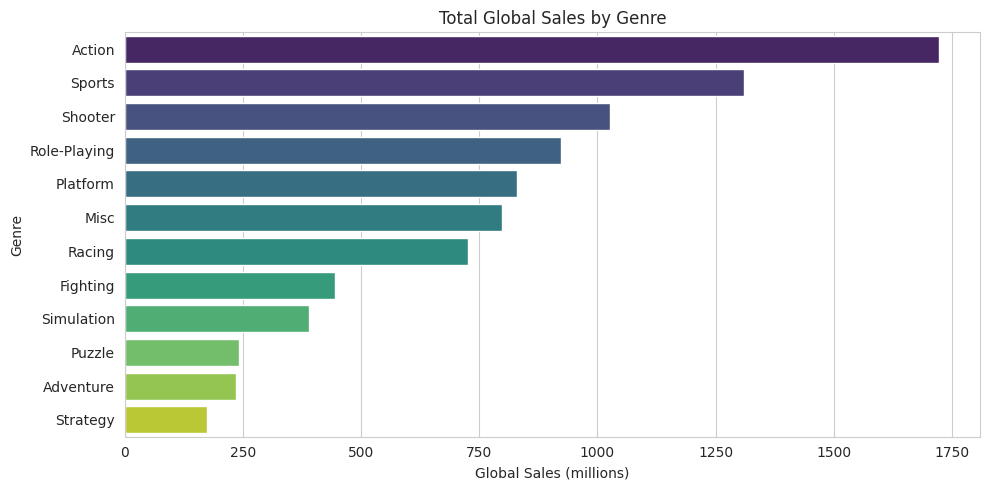

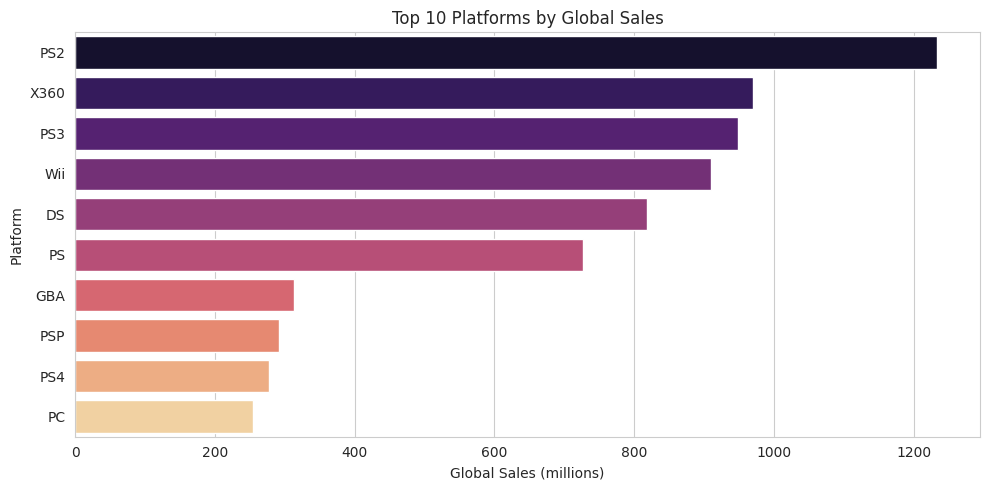

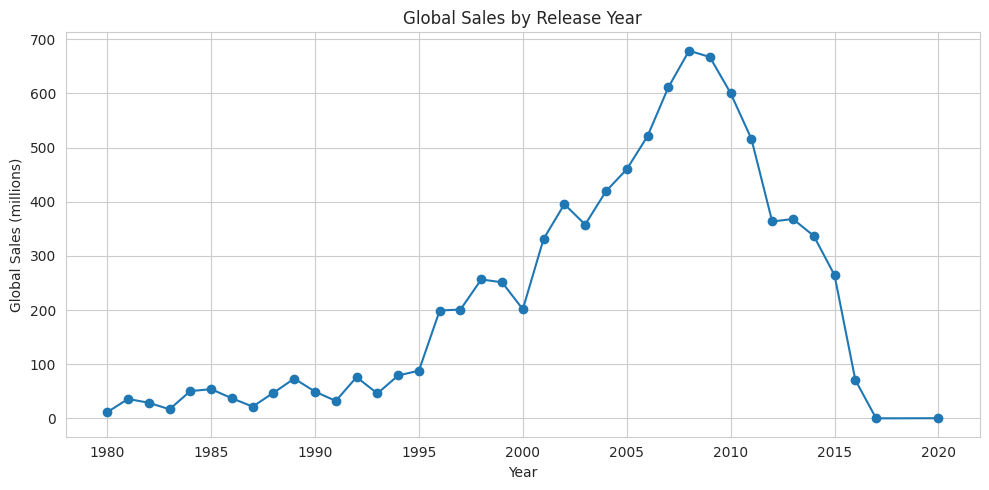

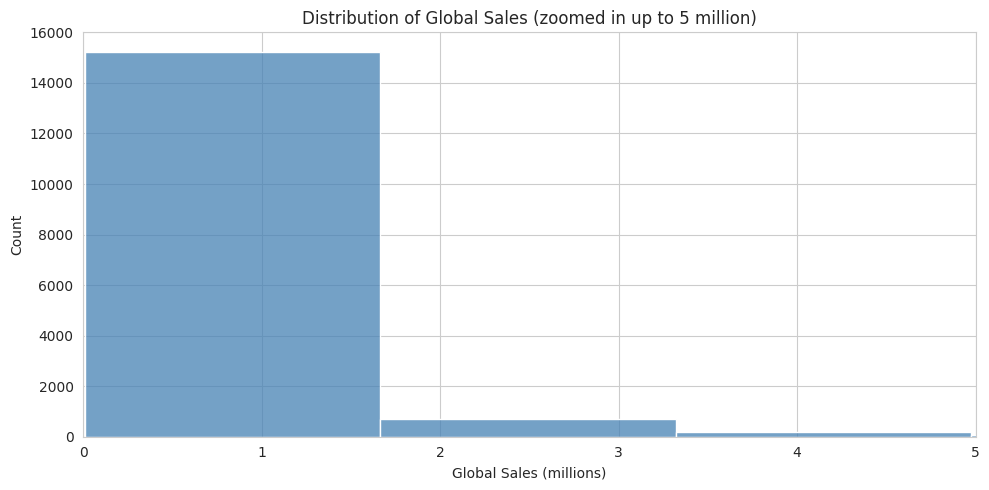

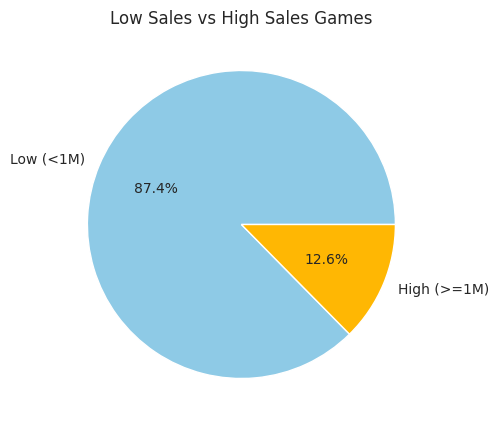

In [14]:
# Graph 1: Total global sales by genre
plt.figure(figsize=(10, 5))
genre_sales = df.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)
sns.barplot(x=genre_sales.values, y=genre_sales.index, palette="viridis")
plt.title("Total Global Sales by Genre")
plt.xlabel("Global Sales (millions)")
plt.tight_layout()
plt.savefig("images/1_genre_sales.png", dpi=150)
plt.show()

# Graph 2: Top 10 platforms by global sales
plt.figure(figsize=(10, 5))
platform_sales = df.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False).head(10)
sns.barplot(x=platform_sales.values, y=platform_sales.index, palette="magma")
plt.title("Top 10 Platforms by Global Sales")
plt.xlabel("Global Sales (millions)")
plt.tight_layout()
plt.savefig("images/2_platform_sales.png", dpi=150)
plt.show()

# Graph 3: Global sales by release year
plt.figure(figsize=(10, 5))
year_sales = df.groupby("Year")["Global_Sales"].sum()
plt.plot(year_sales.index, year_sales.values, marker="o")
plt.title("Global Sales by Release Year")
plt.xlabel("Year")
plt.ylabel("Global Sales (millions)")
plt.tight_layout()
plt.savefig("images/3_year_sales.png", dpi=150)
plt.show()

# Graph 4: Distribution of global sales (zoomed in to 5 million for clarity)
plt.figure(figsize=(10, 5))
sns.histplot(df["Global_Sales"], bins=50, color="steelblue")
plt.xlim(0, 5)
plt.title("Distribution of Global Sales (zoomed in up to 5 million)")
plt.xlabel("Global Sales (millions)")
plt.tight_layout()
plt.savefig("images/4_sales_distribution.png", dpi=150)
plt.show()

# Graph 5: Share of low-sales and high-sales games
low = (df["Global_Sales"] < 1).sum()
high = (df["Global_Sales"] >= 1).sum()
plt.figure(figsize=(5, 5))
plt.pie([low, high], labels=["Low (<1M)", "High (>=1M)"], autopct="%1.1f%%",
        colors=["#8ecae6", "#ffb703"])
plt.title("Low Sales vs High Sales Games")
plt.savefig("images/5_low_vs_high.png", dpi=150)
plt.show()

In [15]:
# Input features and target column
features = ["Platform", "Genre", "Year", "Publisher"]
target = "Global_Sales"

X = df[features].copy()
y = df[target]

# 80% training data, 20% testing data (same split is used for all models)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Publisher has hundreds of unique values, so keep only the top 20 publishers
# and group the rest as "Other". The top 20 are found using training data only,
# so no information from the test data leaks into the model.
top_publishers = X_train["Publisher"].value_counts().head(20).index
X_train["Publisher"] = X_train["Publisher"].where(X_train["Publisher"].isin(top_publishers), "Other")
X_test["Publisher"] = X_test["Publisher"].where(X_test["Publisher"].isin(top_publishers), "Other")

# Preprocessing: one-hot encode the text columns and scale the Year column
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["Platform", "Genre", "Publisher"]),
    ("num", StandardScaler(), ["Year"])
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 13061
Testing rows: 3266


In [16]:
# The three regression models used in this project
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

# Helper function to calculate the evaluation metrics
def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": name,
        "MAE": round(mean_absolute_error(y_true, y_pred), 4),
        "MSE": round(mse, 4),
        "RMSE": round(np.sqrt(mse), 4),
        "R2": round(r2_score(y_true, y_pred), 4),
    }

trained = {}       # stores the trained models
predictions = {}   # stores the test predictions of each model
results = []       # stores the evaluation results

for name, model in models.items():
    # The pipeline applies preprocessing and then trains the model
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    trained[name] = pipe
    predictions[name] = pred
    results.append(evaluate(name, y_test, pred))

# Model comparison table
comparison = pd.DataFrame(results)
comparison.to_csv("results/model_comparison.csv", index=False)
comparison

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.5661,3.9168,1.9791,0.0833
1,Decision Tree,0.5863,4.7211,2.1728,-0.1050
2,Random Forest,0.5529,4.2369,2.0584,0.0083


In [10]:
cv_rows = []

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])

    # Cross-validation is done on the training data only
    mae_scores = -cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
    r2_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")

    cv_rows.append({
        "Model": name,
        "CV Mean MAE": round(mae_scores.mean(), 4),
        "CV Std MAE": round(mae_scores.std(), 4),
        "CV Mean R2": round(r2_scores.mean(), 4),
    })

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv("results/cross_validation_results.csv", index=False)
cv_results

,Model,CV Mean MAE,CV Std MAE,CV Mean R2
0,Linear Regression,0.5234,0.0059,0.1312
1,Decision Tree,0.5611,0.0115,-0.3491
2,Random Forest,0.5073,0.0123,0.0002


In [19]:
# Tune the Decision Tree
dt_pipe = Pipeline([("prep", preprocessor), ("model", DecisionTreeRegressor(random_state=42))])
dt_params = {
    "model__max_depth": [3, 5, 10, 20],
    "model__min_samples_leaf": [1, 5, 10]
}
dt_grid = GridSearchCV(dt_pipe, dt_params, cv=3, scoring="neg_mean_absolute_error", n_jobs=-1)
dt_grid.fit(X_train, y_train)
print("Best Decision Tree settings:", dt_grid.best_params_)

# Tune the Random Forest (small grid and 3 folds to keep the run time low)
# n_jobs is set only in GridSearchCV to avoid nested parallelism
rf_pipe = Pipeline([("prep", preprocessor),
                    ("model", RandomForestRegressor(random_state=42))])
rf_params = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [10, 20],
    "model__min_samples_leaf": [1, 5]
}
rf_grid = GridSearchCV(rf_pipe, rf_params, cv=3, scoring="neg_mean_absolute_error", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best Random Forest settings:", rf_grid.best_params_)

# Evaluate the tuned models on the untouched test data
tuned_rows = []
for name, grid in [("Decision Tree (Tuned)", dt_grid), ("Random Forest (Tuned)", rf_grid)]:
    pred = grid.best_estimator_.predict(X_test)
    trained[name] = grid.best_estimator_
    predictions[name] = pred
    tuned_rows.append(evaluate(name, y_test, pred))

tuning_results = pd.DataFrame(tuned_rows)
tuning_results["Best Params"] = [str(dt_grid.best_params_), str(rf_grid.best_params_)]
tuning_results.to_csv("results/hyperparameter_tuning_results.csv", index=False)

# Compare the original models with the tuned models
full_comparison = pd.concat([comparison, tuning_results.drop(columns="Best Params")], ignore_index=True)
full_comparison.to_csv("results/full_model_comparison.csv", index=False)
full_comparison

Best Decision Tree settings: {'model__max_depth': 20, 'model__min_samples_leaf': 10}
Best Random Forest settings: {'model__max_depth': 20, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.5661,3.9168,1.9791,0.0833
1,Decision Tree,0.5863,4.7211,2.1728,-0.1050
2,Random Forest,0.5529,4.2369,2.0584,0.0083
3,Decision Tree (Tuned),0.5388,3.8530,1.9629,0.0982
4,Random Forest (Tuned),0.5267,3.8611,1.9650,0.0963


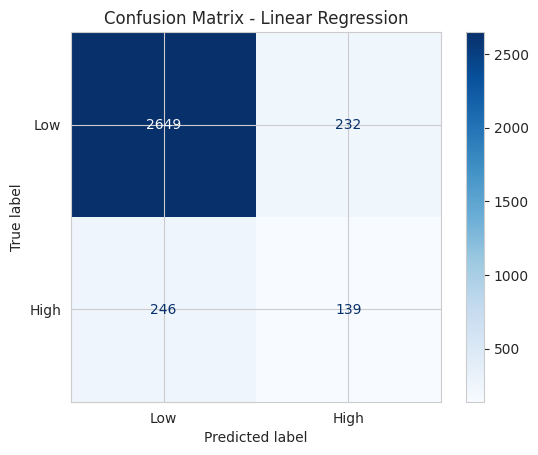

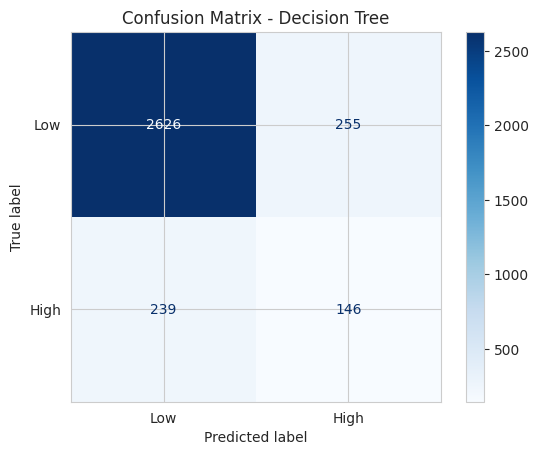

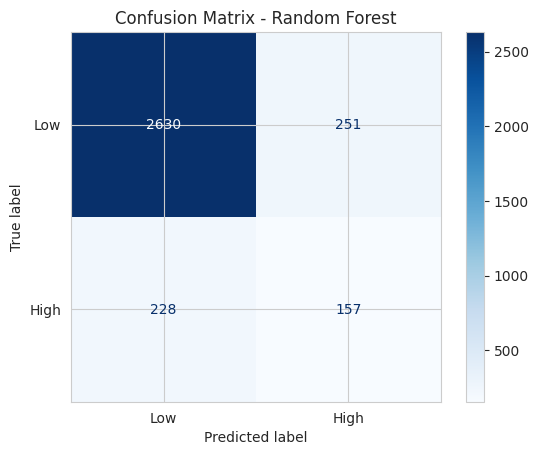

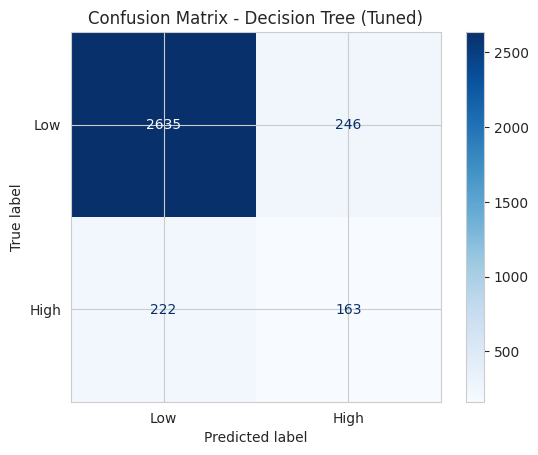

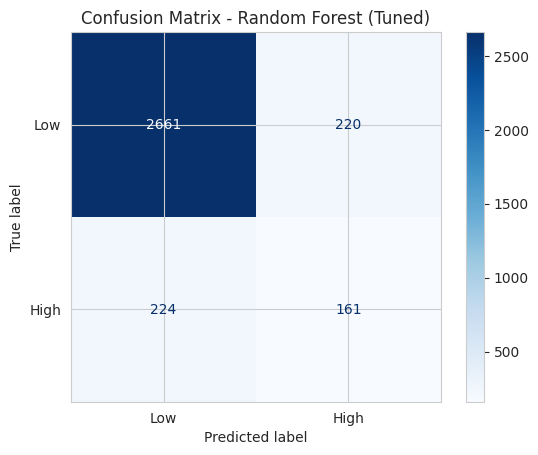

,Model,Accuracy,Precision (High),Recall (High),F1 (High)
0,Linear Regression,0.8536,0.3747,0.3610,0.3677
1,Decision Tree,0.8487,0.3641,0.3792,0.3715
2,Random Forest,0.8533,0.3848,0.4078,0.3960
3,Decision Tree (Tuned),0.8567,0.3985,0.4234,0.4106
4,Random Forest (Tuned),0.8641,0.4226,0.4182,0.4204


In [20]:
# Sales below 1 million are "Low", 1 million or more are "High"
threshold = 1.0

def to_category(values):
    return np.where(np.array(values) >= threshold, "High", "Low")

# Convert the actual sales into categories
actual_cat = to_category(y_test)
cm_summary = []

for name, pred in predictions.items():
    # Convert the predicted sales into categories using the same threshold
    pred_cat = to_category(pred)
    cm = confusion_matrix(actual_cat, pred_cat, labels=["Low", "High"])

    # Create a file-friendly name, e.g. "random_forest_tuned"
    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "").lower()

    # Save the confusion matrix as a CSV file
    pd.DataFrame(cm, index=["Actual Low", "Actual High"],
                 columns=["Predicted Low", "Predicted High"]).to_csv(
        f"results/confusion_matrix_{safe_name}.csv")

    # Save the confusion matrix as an image
    disp = ConfusionMatrixDisplay(cm, display_labels=["Low", "High"])
    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.savefig(f"results/confusion_matrix_{safe_name}.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Classification metrics (High sales is treated as the positive class)
    cm_summary.append({
        "Model": name,
        "Accuracy": round(accuracy_score(actual_cat, pred_cat), 4),
        "Precision (High)": round(precision_score(actual_cat, pred_cat, pos_label="High", zero_division=0), 4),
        "Recall (High)": round(recall_score(actual_cat, pred_cat, pos_label="High", zero_division=0), 4),
        "F1 (High)": round(f1_score(actual_cat, pred_cat, pos_label="High", zero_division=0), 4),
    })

cm_table = pd.DataFrame(cm_summary)
cm_table.to_csv("results/confusion_matrix_metrics.csv", index=False)
cm_table

In [21]:
# Select the model with the lowest RMSE as the final model
best_row = full_comparison.sort_values("RMSE").iloc[0]
best_name = best_row["Model"]
print("Final selected model:", best_name)
print(best_row)

# Save the complete pipeline (preprocessing + model)
joblib.dump(trained[best_name], "models/final_model.pkl")

# Test the saved model: load it and predict sales for a sample game
loaded = joblib.load("models/final_model.pkl")
sample = pd.DataFrame({
    "Platform": ["PS4"],
    "Genre": ["Action"],
    "Year": [2015],
    "Publisher": ["Electronic Arts"]
})
print("Predicted sales (in millions):", round(loaded.predict(sample)[0], 3))

Final selected model: Decision Tree (Tuned)
Model    Decision Tree (Tuned)
MAE                     0.5388
MSE                      3.853
RMSE                    1.9629
R2                      0.0982
Name: 3, dtype: object
Predicted sales (in millions): 3.021


In [22]:
# Zip all output folders and download them to your computer
!zip -r project_files.zip data images results models
files.download("project_files.zip")

  adding: data/ (stored 0%)
  adding: data/cleaned_vgsales.csv (deflated 73%)
  adding: data/vgsales.csv (deflated 73%)
  adding: images/ (stored 0%)
  adding: images/1_genre_sales.png (deflated 23%)
  adding: images/2_platform_sales.png (deflated 24%)
  adding: images/3_year_sales.png (deflated 11%)
  adding: images/5_low_vs_high.png (deflated 10%)
  adding: images/4_sales_distribution.png (deflated 27%)
  adding: results/ (stored 0%)
  adding: results/cross_validation_results.csv (deflated 21%)
  adding: results/confusion_matrix_decision_tree.png (deflated 16%)
  adding: results/confusion_matrix_decision_tree.csv (deflated 26%)
  adding: results/confusion_matrix_random_forest.csv (deflated 26%)
  adding: results/confusion_matrix_linear_regression.csv (deflated 26%)
  adding: results/confusion_matrix_metrics.csv (deflated 40%)
  adding: results/confusion_matrix_random_forest.png (deflated 17%)
  adding: results/model_comparison.csv (deflated 16%)
  adding: results/hyperparameter_tunin

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>